本 notebook 是 [M01.1 Python 进阶](../notes/01-advanced-python.qmd) 的实例讲解。每一节都用一个
材料模拟里常见的小场景，把讲义中的机制直接“跑出来”：

1. 数据模型：让一个 `Structure` 类支持 `len`、索引、切片、迭代和 `in`；
2. 惰性计算：逐帧读取轨迹的生成器与一次性读入的列表，内存差多少；
3. 闭包与装饰器：循环里的 lambda 为什么全都一样；带 `functools.wraps` 的计时装饰器；`lru_cache` 的边界；
4. 上下文管理器：异常发生时也能恢复工作目录和浮点错误设置；
5. `dataclass` 与类型注解：冻结的模拟参数、`__post_init__` 校验、可变默认值陷阱；
6. 导入系统：`sys.modules` 缓存、`importlib.reload` 与过期的 `from ... import`；
7. 异常设计：领域异常层次、`raise ... from`、`add_note`；
8. 序列化：手写 extxyz 读写的往返检验、JSON 的 NaN 与 NumPy 类型、`pickle` 的任意调用与类改名问题。

**运行方式**：在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行。全部单元在
CPU 上约 10 秒内完成，所有文件读写都在临时目录中进行。改动代码后可用 `make nb M=01` 重新执行并保存输出。

In [1]:
import contextlib
import dataclasses
import functools
import importlib
import io
import json
import operator
import os
import pickle
import sys
import tempfile
import time
import tracemalloc
from collections.abc import Iterator
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats

from semiai.plotting import BLUE, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(0)
np.set_printoptions(precision=4, suppress=True)
print(sys.version.split()[0])

3.12.13


## 1. 数据模型：让自定义类像内置容器一样工作

Python 的 `len(x)`、`x[i]`、`for a in x`、`a in x` 不是在调用对象的某个“普通方法”，而是由解释器去
**类型**上查找 `__len__`、`__getitem__`、`__iter__`、`__contains__` 这些特殊方法。下面的
`Structure` 只实现了 `__len__`、`__getitem__`、`__repr__` 和 `__eq__`，看看哪些行为“免费”获得。

In [2]:
class Structure:
    """最小的原子结构容器：元素符号与笛卡尔坐标（Å）。"""

    def __init__(self, symbols: list[str], positions: np.ndarray) -> None:
        positions = np.asarray(positions, dtype=float)
        if positions.shape != (len(symbols), 3):
            raise ValueError(f"positions 形状应为 ({len(symbols)}, 3)，实际为 {positions.shape}")
        self.symbols = list(symbols)
        self.positions = positions

    def __len__(self) -> int:
        return len(self.symbols)

    def __getitem__(self, index):
        if isinstance(index, slice):  # 切片返回同类型对象，而不是 list
            return Structure(self.symbols[index], self.positions[index])
        return self.symbols[index], self.positions[index]

    def __repr__(self) -> str:
        formula = "".join(f"{s}{self.symbols.count(s)}" for s in dict.fromkeys(self.symbols))
        return f"Structure({formula}, natoms={len(self)})"

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Structure):
            return NotImplemented
        return self.symbols == other.symbols and np.array_equal(self.positions, other.positions)


s = Structure(["Ge", "Sb", "Te", "Te"], rng.uniform(0, 6, size=(4, 3)))
print("repr          :", s)
print("len           :", len(s))
print("s[0]          :", s[0][0], s[0][1])
print("s[1:3]        :", s[1:3])
print("for 循环      :", [sym for sym, _ in s])
print("反向迭代      :", [sym for sym, _ in reversed(s)])
print("__hash__      :", Structure.__hash__)

repr          : Structure(Ge1Sb1Te2, natoms=4)
len           : 4
s[0]          : Ge [3.8218 1.6187 0.2458]
s[1:3]        : Structure(Sb1Te1, natoms=2)
for 循环      : ['Ge', 'Sb', 'Te', 'Te']
反向迭代      : ['Te', 'Te', 'Sb', 'Ge']
__hash__      : None


读法：

- 没有写 `__iter__`，`for` 循环照样能用。解释器发现没有 `__iter__` 时，会退回到旧的“序列协议”：
  从 0 开始调用 `__getitem__`，直到抛出 `IndexError`。`reversed` 同理，用的是 `__len__` + `__getitem__`。
- 定义了 `__eq__` 却没定义 `__hash__`，Python 会把 `__hash__` 设为 `None`：对象变得不可哈希，不能放进
  `set` 或作为 `dict` 的键。这是有意为之，因为“相等的对象哈希必须相等”这条约定无法自动保证。

`in` 运算符在没有 `__contains__` 时同样退回到逐个迭代比较。这里元素是 `(符号, 数组)` 元组，元组比较会
对 NumPy 数组调用 `==`，得到的是逐元素布尔数组，`bool()` 会报错。这是自定义容器里的典型坑：

In [3]:
try:
    print(("Te", s.positions[2]) in s)
except ValueError as err:
    print("ValueError:", err)

# 特殊方法在类型上查找，而不是实例上：给实例绑定 __len__ 没有用
s.__len__ = lambda: 999
print("实例上的 __len__ 被忽略，len(s) =", len(s))

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()
实例上的 __len__ 被忽略，len(s) = 4


前两个原子的符号与 `"Te"` 不同，元组比较在第一项就结束；到第三个原子时符号相同，需要接着
比较数组，`bool(array == array)` 就抛出了 `ValueError`。需要 `in` 的语义时，应当显式实现
`__contains__`，用 `np.allclose` 之类的规则定义“包含”。

## 2. 惰性计算：逐帧读取轨迹

把一条 extxyz 轨迹写进临时文件，然后对比两种读法的内存峰值：先全部读进列表，再处理；用生成器逐帧
`yield`，处理完一帧就丢掉一帧。用 `tracemalloc` 统计 Python 分配的内存峰值。

In [4]:
def write_xyz_trajectory(path: Path, n_frames: int, n_atoms: int, seed: int = 0) -> None:
    """写一条合成轨迹：每帧 n_atoms 个原子，坐标为随机数（只用来测 I/O，不代表物理体系）。"""
    r = np.random.default_rng(seed)
    with path.open("w") as f:
        for step in range(n_frames):
            pos = r.uniform(0, 20, size=(n_atoms, 3))
            f.write(f"{n_atoms}\nstep={step} Properties=species:S:1:pos:R:3\n")
            f.writelines(f"Si {x:.8f} {y:.8f} {z:.8f}\n" for x, y, z in pos)


def iter_frames(path: Path) -> Iterator[np.ndarray]:
    """逐帧产出坐标数组，shape (n_atoms, 3)。文件句柄在生成器结束或被关闭时释放。"""
    with path.open() as f:
        while header := f.readline():
            n = int(header)
            f.readline()  # 注释行
            yield np.loadtxt([f.readline() for _ in range(n)], usecols=(1, 2, 3))


def read_all_frames(path: Path) -> list[np.ndarray]:
    return list(iter_frames(path))


def peak_mib(func, *args) -> tuple[float, object]:
    tracemalloc.start()
    result = func(*args)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 2**20, result


def mean_z_eager(path: Path) -> float:
    frames = read_all_frames(path)
    return float(np.mean([fr[:, 2].mean() for fr in frames]))


def mean_z_lazy(path: Path) -> float:
    total, count = 0.0, 0
    for fr in iter_frames(path):
        total += fr[:, 2].mean()
        count += 1
    return total / count


rows = []
with tempfile.TemporaryDirectory() as tmp:
    for n_frames in (25, 50, 100, 200, 400):
        path = Path(tmp) / f"traj_{n_frames}.xyz"
        write_xyz_trajectory(path, n_frames, n_atoms=500)
        mem_eager, z_eager = peak_mib(mean_z_eager, path)
        mem_lazy, z_lazy = peak_mib(mean_z_lazy, path)
        assert np.isclose(z_eager, z_lazy)
        rows.append({"帧数": n_frames, "文件大小 / MiB": path.stat().st_size / 2**20,
                     "列表峰值 / MiB": mem_eager, "生成器峰值 / MiB": mem_lazy})
mem = pd.DataFrame(rows).set_index("帧数")
mem.round(2)

,文件大小 / MiB,列表峰值 / MiB,生成器峰值 / MiB
帧数,,,
25,0.45,0.36,0.1
50,0.90,0.65,0.1
100,1.79,1.22,0.1
200,3.58,2.39,0.1
400,7.17,4.70,0.1


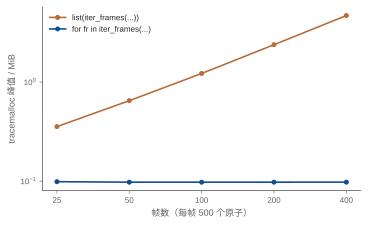

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(mem.index, mem["列表峰值 / MiB"], "o-", color=ORANGE, label="list(iter_frames(...))")
ax.plot(mem.index, mem["生成器峰值 / MiB"], "o-", color=BLUE, label="for fr in iter_frames(...)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.minorticks_off()
ax.set_xticks(mem.index, [str(n) for n in mem.index])
ax.set_xlabel("帧数（每帧 500 个原子）")
ax.set_ylabel("tracemalloc 峰值 / MiB")
ax.legend()
fig.tight_layout()
plt.show()

读法：列表版本的峰值随帧数线性增长（每帧 500×3 个 float64 约 12 KB，外加解析时的临时字符串），
生成器版本几乎不随帧数变化，只取决于单帧大小。两种写法算出的平均 $z$ 完全一致（代码里有 `assert`）。

生成器的代价是**只能遍历一次**，而且一旦被部分消费，剩下的帧就从断点继续：

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "short.xyz"
    write_xyz_trajectory(path, n_frames=5, n_atoms=3)
    frames = iter_frames(path)
    first = next(frames)
    print("取走第 1 帧后，剩余帧数：", sum(1 for _ in frames))
    print("再遍历一次：", sum(1 for _ in frames), "帧（生成器已耗尽，不会报错，只是空）")
    frames.close()  # 显式关闭：触发生成器内 with 块的清理

取走第 1 帧后，剩余帧数： 4
再遍历一次： 0 帧（生成器已耗尽，不会报错，只是空）


“静默地变空”比报错更危险：同一个生成器被传给两个分析函数时，第二个函数会拿到 0 帧并给出
`nan` 或空图。需要多次遍历时，传入能重新打开文件的可迭代对象（例如一个带 `__iter__` 的类，每次
调用都返回新的生成器），而不是一个生成器对象。

## 3. 闭包与装饰器

### 3.1 循环里创建的函数为什么全都一样

闭包捕获的是**变量**（一个 cell），不是变量在创建时的值。

In [7]:
cutoffs = [2.5, 3.0, 3.5]
late = [lambda r: r < rc for rc in cutoffs]  # noqa: B023 —— 故意演示后期绑定
early = [lambda r, rc=rc: r < rc for rc in cutoffs]  # 默认参数在定义时求值
bound = [functools.partial(operator.gt, rc) for rc in cutoffs]  # gt(rc, r) 即 rc > r

r = 2.8
print("late  :", [f(r) for f in late])
print("early :", [f(r) for f in early])
print("partial:", [f(r) for f in bound])
print("late[0] 的闭包单元：", late[0].__closure__, "→ 列表推导自己的作用域里只有一个 rc")


def make_counter():
    count = 0

    def step():
        nonlocal count  # 没有 nonlocal 时，count += 1 会把 count 当成局部变量而报 UnboundLocalError
        count += 1
        return count

    return step


c = make_counter()
print("计数器：", c(), c(), c(), "；cell 内容 =", c.__closure__[0].cell_contents)

late  : [True, True, True]
early : [False, True, True]
partial: [False, True, True]
late[0] 的闭包单元： (<cell at 0x1148f1db0: float object at 0x114863d90>,) → 列表推导自己的作用域里只有一个 rc
计数器： 1 2 3 ；cell 内容 = 3


读法：`late` 中三个函数共享同一个 cell，循环结束时 `rc = 3.5`，所以三个判断结果相同。用默认参数
或 `functools.partial` 在创建时把值“冻结”下来，才得到三个不同的截断判据。

### 3.2 装饰器：计时与调用计数

装饰器就是“接收函数、返回函数”的函数，`@timed` 等价于 `f = timed(f)`。`functools.wraps` 把原函数的
`__name__`、`__doc__`、`__wrapped__` 复制到包装函数上，否则日志、文档和 `inspect` 都会看到 `wrapper`。

In [8]:
def timed(func):
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        try:
            return func(*args, **kwargs)
        finally:
            wrapper.calls += 1
            wrapper.total_s += time.perf_counter() - t0

    wrapper.calls = 0
    wrapper.total_s = 0.0
    return wrapper


def timed_no_wraps(func):
    def wrapper(*args, **kwargs):
        return func(*args, **kwargs)

    return wrapper


@timed
def pair_distances(pos: np.ndarray) -> np.ndarray:
    """所有原子对的距离，shape (n, n)。"""
    diff = pos[:, None, :] - pos[None, :, :]
    return np.sqrt((diff**2).sum(-1))


for _ in range(20):
    pair_distances(rng.uniform(0, 10, size=(300, 3)))
print(f"调用 {pair_distances.calls} 次，累计 {pair_distances.total_s * 1e3:.1f} ms（与机器有关）")
print("有 wraps   :", pair_distances.__name__, "|", pair_distances.__doc__)
print("没有 wraps :", timed_no_wraps(pair_distances.__wrapped__).__name__)

调用 20 次，累计 21.8 ms（与机器有关）
有 wraps   : pair_distances | 所有原子对的距离，shape (n, n)。
没有 wraps : wrapper


### 3.3 `lru_cache`：只适用于纯函数和可哈希参数

`functools.lru_cache` 用参数做字典键缓存结果。它有两个边界：参数必须可哈希（NumPy 数组不行）；
被缓存的返回值如果是可变对象，调用方修改它会**污染缓存**。

In [9]:
@functools.cache  # 即 lru_cache(maxsize=None)
def lattice_vectors(a: float, kind: str) -> np.ndarray:
    """立方晶格的基矢，shape (3, 3)，单位 Å。"""
    base = {"sc": np.eye(3), "fcc": 0.5 * (np.ones((3, 3)) - np.eye(3))}[kind]
    return a * base


v1 = lattice_vectors(5.43, "fcc")
v1 *= 2  # 调用方原地修改了返回的数组……
v2 = lattice_vectors(5.43, "fcc")
print("缓存信息   :", lattice_vectors.cache_info())
print("v2 第一行  :", v2[0], " ← 第二次调用拿到的是被改过的同一个对象：", v2 is v1)

try:
    lattice_vectors(np.float64(5.43), "fcc")  # 可以：np.float64 可哈希
    lattice_vectors(np.array([5.43]), "fcc")
except TypeError as err:
    print("TypeError  :", err)

缓存信息   : CacheInfo(hits=1, misses=1, maxsize=None, currsize=1)
v2 第一行  : [0.   5.43 5.43]  ← 第二次调用拿到的是被改过的同一个对象： True
TypeError  : unhashable type: 'numpy.ndarray'


读法：第二次调用命中缓存（`hits=1`），返回的正是第一次被原地乘以 2 的数组。缓存可变对象时，要么返回
只读副本（`arr.copy()` 或 `arr.setflags(write=False)`），要么不缓存。

## 4. 上下文管理器：出错时也要恢复现场

`with` 保证 `__exit__` 一定执行，无论代码块是正常结束、`return` 还是抛出异常。下面用
`contextlib.contextmanager` 写一个“临时切换工作目录”的管理器（Python 3.11 起标准库也有
`contextlib.chdir`），并和 `np.errstate` 组合使用。

In [10]:
@contextlib.contextmanager
def working_directory(path: Path):
    previous = Path.cwd()
    os.chdir(path)
    try:
        yield path
    finally:  # 没有 finally，代码块里一旦抛异常，工作目录就永远停在 path
        os.chdir(previous)


start = Path.cwd()
with tempfile.TemporaryDirectory() as tmp:
    try:
        with working_directory(Path(tmp)), np.errstate(divide="raise"):
            Path("INCAR").write_text("ENCUT = 520\n")
            print("块内 cwd 是临时目录：", Path.cwd().resolve() == Path(tmp).resolve())
            np.log(np.array([1.0, 0.0]))  # divide="raise" 时，log(0) 抛 FloatingPointError
    except FloatingPointError as err:
        print("捕获：", type(err).__name__, err)
print("cwd 已恢复：", Path.cwd() == start)
print("errstate 已恢复：", np.geterr()["divide"])

块内 cwd 是临时目录： True
捕获： FloatingPointError divide by zero encountered in log
cwd 已恢复： True
errstate 已恢复： warn


`__exit__` 的返回值决定异常是否被吞掉：返回真值表示“已处理”。`contextlib.suppress` 就是这样实现的，
这也是自己写 `__exit__` 时最容易出错的地方。

In [11]:
class Swallow:
    def __enter__(self):
        return self

    def __exit__(self, exc_type, exc, tb):
        self.seen = exc_type
        return True  # 吞掉一切异常：几乎总是错误的设计


with Swallow() as sw:
    raise RuntimeError("SCF 不收敛")
print("异常被吞掉了，程序继续运行；__exit__ 看到的是", sw.seen.__name__)

with contextlib.suppress(FileNotFoundError):
    Path("/nonexistent/OUTCAR").read_text()
print("suppress 只吞掉指定的异常类型")

异常被吞掉了，程序继续运行；__exit__ 看到的是 RuntimeError
suppress 只吞掉指定的异常类型


## 5. `dataclass` 与类型注解

`dataclass` 根据类型注解自动生成 `__init__`、`__repr__`、`__eq__`。`frozen=True` 再生成禁止赋值的
`__setattr__`，并且因为对象不可变，可以安全地生成 `__hash__`。类型注解本身**不做运行时检查**，需要
校验时写在 `__post_init__` 里。

In [12]:
@dataclasses.dataclass(frozen=True)
class MDSettings:
    timestep_fs: float
    temperature_K: float
    ensemble: str = "NVT"
    thermostat_tau_fs: float = 100.0

    def __post_init__(self) -> None:
        if self.ensemble not in {"NVE", "NVT", "NPT"}:
            raise ValueError(f"未知系综 {self.ensemble!r}")
        if not 0 < self.timestep_fs <= 5:
            raise ValueError(f"timestep_fs={self.timestep_fs} 超出 (0, 5] fs")


md = MDSettings(timestep_fs=1.0, temperature_K=600)
print(md)
print("可哈希，可作字典键：", {md: "run-001"}[MDSettings(1.0, 600)])
print("replace 生成新对象：", dataclasses.replace(md, temperature_K=900))

for bad in (dict(timestep_fs=10, temperature_K=300), dict(timestep_fs=1, temperature_K=300,
                                                         ensemble="nvt")):
    try:
        MDSettings(**bad)
    except ValueError as err:
        print("ValueError:", err)

try:
    md.temperature_K = 1200
except dataclasses.FrozenInstanceError as err:
    print("FrozenInstanceError:", err)

print("注解不会被检查：", MDSettings(timestep_fs=1.0, temperature_K="600K"))

MDSettings(timestep_fs=1.0, temperature_K=600, ensemble='NVT', thermostat_tau_fs=100.0)
可哈希，可作字典键： run-001
replace 生成新对象： MDSettings(timestep_fs=1.0, temperature_K=900, ensemble='NVT', thermostat_tau_fs=100.0)
ValueError: timestep_fs=10 超出 (0, 5] fs
ValueError: 未知系综 'nvt'
FrozenInstanceError: cannot assign to field 'temperature_K'
注解不会被检查： MDSettings(timestep_fs=1.0, temperature_K='600K', ensemble='NVT', thermostat_tau_fs=100.0)


读法：最后一行把字符串 `"600K"` 传给了注解为 `float` 的字段，没有任何报错。类型注解是给静态检查器
（mypy、pyright）和读者看的；运行时的约束要么写在 `__post_init__`，要么交给 pydantic 一类的库。

可变默认值是另一个经典陷阱。`dataclass` 直接拒绝 `list` 默认值，强制使用 `default_factory`：

In [13]:
try:
    @dataclasses.dataclass
    class BadRun:
        tags: list = []
except ValueError as err:
    print("ValueError:", err)


@dataclasses.dataclass
class Run:
    tags: list[str] = dataclasses.field(default_factory=list)


a, b = Run(), Run()
a.tags.append("amorphous")
print("各自独立的列表：", a.tags, b.tags)


def append_tag_bad(tag, tags=[]):  # noqa: B006 —— 故意演示：默认值在 def 时只求值一次
    tags.append(tag)
    return tags


first = append_tag_bad("a")
print("第一次调用：", first)
second = append_tag_bad("b")
print("第二次调用：", second, "；两次返回同一个列表：", first is second)

ValueError: mutable default <class 'list'> for field tags is not allowed: use default_factory
各自独立的列表： ['amorphous'] []
第一次调用： ['a']
第二次调用： ['a', 'b'] ；两次返回同一个列表： True


## 6. 导入系统：缓存、重载与过期的引用

`import m` 先查 `sys.modules`。命中就直接返回已有的模块对象，**模块顶层代码不会再次执行**。
`importlib.reload(m)` 会重新执行顶层代码，但复用同一个模块对象；而 `from m import x` 得到的是当时
那个对象的另一个名字，重载后不会自动更新。下面在临时目录里写一个模块来观察这些行为。

In [14]:
with tempfile.TemporaryDirectory() as tmp:
    mod_path = Path(tmp) / "mlip_units.py"
    mod_path.write_text('print("  [执行 mlip_units 顶层代码]")\nEV_TO_KJMOL = 96.485\n')
    sys.path.insert(0, tmp)
    try:
        import mlip_units
        import mlip_units as again  # 第二次 import：命中 sys.modules，不再执行顶层代码

        print("同一个对象：", again is mlip_units)
        print("在 sys.modules 中：", "mlip_units" in sys.modules)
        from mlip_units import EV_TO_KJMOL

        mod_path.write_text('print("  [执行 mlip_units 顶层代码]")\nEV_TO_KJMOL = 96.4853321\n')
        os.utime(mod_path, (time.time() + 5, time.time() + 5))  # 让字节码缓存判定源文件已变
        importlib.invalidate_caches()
        reloaded = importlib.reload(mlip_units)
        print("reload 返回同一个对象：", reloaded is mlip_units)
        print("mlip_units.EV_TO_KJMOL =", mlip_units.EV_TO_KJMOL)
        print("from 导入的名字仍是旧值 =", EV_TO_KJMOL)
    finally:
        sys.path.remove(tmp)
        sys.modules.pop("mlip_units", None)

  [执行 mlip_units 顶层代码]
同一个对象： True
在 sys.modules 中： True
  [执行 mlip_units 顶层代码]
reload 返回同一个对象： True
mlip_units.EV_TO_KJMOL = 96.4853321
from 导入的名字仍是旧值 = 96.485


读法：顶层的 `print` 只在第一次 `import` 和 `reload` 时各执行一次。`reload` 之后，通过模块属性
访问得到新值，`from ... import` 绑定的名字仍指向旧值。在 notebook 里改了自己包的源码后，最稳妥的
做法是重启内核；`%autoreload` 也只能部分缓解这个问题。

## 7. 异常设计：让调用方能区分“哪一种失败”

为自己的库定义一个根异常，再按调用方需要做出的不同反应细分子类。异常对象可以携带结构化信息，
`raise ... from err` 保留原始原因，`add_note`（Python 3.11+）在向上传递时补充上下文。

In [15]:
class SimulationError(Exception):
    """本库全部异常的根类：调用方可以一次捕获本库的所有失败。"""


class ConvergenceError(SimulationError):
    def __init__(self, steps: int, residual: float) -> None:
        super().__init__(f"{steps} 步后未收敛，残差 {residual:.2e}")
        self.steps = steps
        self.residual = residual


class InputError(SimulationError, ValueError):
    """输入错误；同时是 ValueError，让不认识本库的调用方也能按通用类型捕获。"""


def relax(forces_norm: float, max_steps: int = 50) -> int:
    for step in range(1, max_steps + 1):
        forces_norm *= 0.9
        if forces_norm < 1e-3:
            return step
    raise ConvergenceError(max_steps, forces_norm)


def parse_ediff(text: str) -> float:
    try:
        return float(text)
    except ValueError as err:
        raise InputError(f"EDIFF 无法解析：{text!r}") from err


for f0 in (0.05, 5.0):
    try:
        print(f"初始力 {f0}：{relax(f0)} 步收敛")
    except ConvergenceError as err:
        err.add_note(f"初始力范数 {f0} eV/Å；可以增大 max_steps 或换用 FIRE")
        print(f"初始力 {f0}：ConvergenceError(steps={err.steps}, residual={err.residual:.3f})")
        print("  notes:", err.__notes__)

try:
    parse_ediff("1e-6eV")
except ValueError as err:  # 用通用类型也能捕获
    print(type(err).__name__, "|", err, "| 原因：", repr(err.__cause__))

初始力 0.05：38 步收敛
初始力 5.0：ConvergenceError(steps=50, residual=0.026)
  notes: ['初始力范数 5.0 eV/Å；可以增大 max_steps 或换用 FIRE']
InputError | EDIFF 无法解析：'1e-6eV' | 原因： ValueError("could not convert string to float: '1e-6eV'")


读法：调用方可以按需选择捕获粒度：`except ConvergenceError` 决定是否重试，`except SimulationError`
兜底本库的一切失败，而 `InputError` 同时继承 `ValueError`，不了解本库的代码也能正确处理。
`__cause__` 保留了原始的 `ValueError`，traceback 里会显示“The above exception was the direct cause...”。

## 8. 序列化：文本格式、JSON 与 pickle

### 8.1 手写 extxyz 的往返检验

extxyz 的第二行是 `key=value` 对，`Properties=species:S:1:pos:R:3` 声明后续每行的列：名字、类型
（S 字符串，R 实数，I 整数，L 逻辑）、列数。下面写一个最小的读写器，检验“写出再读回”是否无损，
并观察坐标格式的有效数字如何决定误差。

In [16]:
def write_extxyz(f: io.TextIOBase, symbols: list[str], positions: np.ndarray, cell: np.ndarray,
                 fmt: str = "{:.17g}") -> None:
    lattice = " ".join(fmt.format(float(x)) for x in cell.ravel())
    f.write(f'{len(symbols)}\nLattice="{lattice}" Properties=species:S:1:pos:R:3 pbc="T T T"\n')
    for sym, p in zip(symbols, positions, strict=True):
        f.write(sym + " " + " ".join(fmt.format(float(x)) for x in p) + "\n")


def read_extxyz(f: io.TextIOBase) -> tuple[list[str], np.ndarray, np.ndarray]:
    n = int(f.readline())
    comment = f.readline()
    lattice = comment.split('Lattice="')[1].split('"')[0]
    cell = np.array(lattice.split(), dtype=float).reshape(3, 3)
    rows = [f.readline().split() for _ in range(n)]
    return [r[0] for r in rows], np.array([r[1:4] for r in rows], dtype=float), cell


symbols = ["Ge", "Sb", "Te"] * 20
cell = np.diag([12.3, 12.3, 12.3]) + rng.normal(0, 0.01, (3, 3))
pos = rng.uniform(0, 1, size=(60, 3)) @ cell

rows = []
for fmt in ("{:.6f}", "{:.8g}", "{:.15g}", "{:.17g}", "{!r}"):
    buf = io.StringIO()
    write_extxyz(buf, symbols, pos, cell, fmt=fmt)
    buf.seek(0)
    sym2, pos2, cell2 = read_extxyz(buf)
    rows.append({
        "格式": fmt,
        "符号一致": sym2 == symbols,
        "位置完全相等": np.array_equal(pos2, pos),
        "最大绝对误差 / Å": f"{np.abs(pos2 - pos).max():.1e}",
        "每原子字节数": len(buf.getvalue()) // len(symbols),
    })
pd.DataFrame(rows).set_index("格式")

,符号一致,位置完全相等,最大绝对误差 / Å,每原子字节数
格式,,,,
{:.6f},True,False,5.0e-07,33
{:.8g},True,False,4.9e-07,35
{:.15g},True,False,5.0e-14,57
{:.17g},True,True,0.0e+00,63
{!r},True,True,0.0e+00,62


读法：`%.6f` 的误差约 $5\times10^{-7}$ Å，对结构本身无关紧要，但如果拿读回的坐标做有限差分力检验
（步长常取 $10^{-3}$–$10^{-4}$ Å），这个截断误差就不能忽略。`.17g` 和 `repr` 能让 float64 精确往返
（讲义 [往返所需的有效数字](../notes/01-advanced-python.qmd#eq-roundtrip)），`.15g` 则不保证。

### 8.2 JSON：NaN 与 NumPy 类型

In [17]:
record = {"energy_eV": float("nan"), "converged": False}
text = json.dumps(record)
print("默认输出      :", text, " ← NaN 不是合法 JSON，很多其他语言的解析器会拒绝")
try:
    json.dumps(record, allow_nan=False)
except ValueError as err:
    print("allow_nan=False:", err)

for value in (np.float64(1.5), np.float32(1.5), np.int64(3), np.array([1.0, 2.0])):
    try:
        json.dumps({"x": value})
        print(f"{type(value).__name__:>8}: 可以序列化（np.float64 是 float 的子类）")
    except TypeError as err:
        print(f"{type(value).__name__:>8}: TypeError: {err}")

x = 0.1 + 0.2
print("float 经 JSON 往返是否精确：", json.loads(json.dumps(x)) == x)
print("json 写出的文本：", json.dumps(x), "= repr(x)：", repr(x))

默认输出      : {"energy_eV": NaN, "converged": false}  ← NaN 不是合法 JSON，很多其他语言的解析器会拒绝
allow_nan=False: Out of range float values are not JSON compliant: nan
 float64: 可以序列化（np.float64 是 float 的子类）
 float32: TypeError: Object of type float32 is not JSON serializable
   int64: TypeError: Object of type int64 is not JSON serializable
 ndarray: TypeError: Object of type ndarray is not JSON serializable
float 经 JSON 往返是否精确： True
json 写出的文本： 0.30000000000000004 = repr(x)： 0.30000000000000004


读法：只有 `np.float64` 能直接写进 JSON，因为它恰好继承自 Python 的 `float`；`np.float32`、`np.int64`
和数组都需要先 `.item()` / `.tolist()`。另一方面，Python 的 `json` 写 float 用的是最短往返表示，
读回来与原值完全相等。

### 8.3 pickle：加载即执行，以及类改名后的兼容问题

pickle 不存“数据”，而是存一段重建对象的指令。对象可以通过 `__reduce__` 指定“加载时调用哪个函数、传
哪些参数”。下面让它调用无害的 `print`，但同样的机制可以调用 `os.system`。

In [18]:
class Innocent:
    def __reduce__(self):
        return (print, ("  >>> 这一行是在 pickle.loads 期间被调用的 print 打印的",))


payload = pickle.dumps(Innocent())
print("payload 中引用的可调用对象：", b"builtins" in payload and b"print" in payload)
print("开始 loads ...")
obj = pickle.loads(payload)
print("loads 返回的是 print 的返回值：", obj)


class RestrictedUnpickler(pickle.Unpickler):
    """只允许重建白名单中的类（Python 文档 'Restricting Globals' 一节的做法）。"""

    allowed = {("builtins", "list"), ("builtins", "dict")}

    def find_class(self, module, name):
        if (module, name) in self.allowed:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"禁止加载 {module}.{name}")


try:
    RestrictedUnpickler(io.BytesIO(payload)).load()
except pickle.UnpicklingError as err:
    print("RestrictedUnpickler:", err)

payload 中引用的可调用对象： True
开始 loads ...
  >>> 这一行是在 pickle.loads 期间被调用的 print 打印的
loads 返回的是 print 的返回值： None
RestrictedUnpickler: 禁止加载 builtins.print


兼容性问题来自同一个机制：pickle 按“模块路径 + 类名”引用类，不保存类的代码。类改名、移动模块，
旧文件就读不出来了。

In [19]:
with tempfile.TemporaryDirectory() as tmp:
    source = "class Frame:\n    def __init__(self, e):\n        self.e = e\n"
    (Path(tmp) / "mydata.py").write_text(source)
    sys.path.insert(0, tmp)
    try:
        import mydata

        blob = pickle.dumps(mydata.Frame(-123.4))
        print("pickle 里记录的引用：", [p for p in (b"mydata", b"Frame") if p in blob])
        print("正常读回：", pickle.loads(blob).e)
        del mydata.Frame  # 模拟“重构时把 Frame 改名为 Snapshot”
        try:
            pickle.loads(blob)
        except AttributeError as err:
            print("改名后读回：AttributeError:", err)
    finally:
        sys.path.remove(tmp)
        sys.modules.pop("mydata", None)

pickle 里记录的引用： [b'mydata', b'Frame']
正常读回： -123.4
改名后读回：AttributeError: Can't get attribute 'Frame' on <module 'mydata' from '/var/folders/ly/np3n926x7t1fsg2y0fg7jqnh0000gn/T/tmpow_6cib6/mydata.py'>


读法：pickle 适合“同一份代码、短期缓存”的场景；跨版本、跨机器、要长期保存或与别人交换的数据，用
自描述的格式（extxyz、HDF5、JSON + `.npy`），并在文件里写入格式版本号。

## 小结

- 特殊方法在类型上查找；只实现 `__len__` + `__getitem__` 就能获得迭代和 `reversed`，但 `in` 的默认
  行为可能和 NumPy 数组冲突；定义 `__eq__` 会让对象不可哈希。
- 生成器把内存峰值从“随帧数线性增长”降到“只取决于单帧”，代价是只能遍历一次，耗尽后静默为空。
- 闭包捕获变量而不是值；装饰器要用 `functools.wraps`；`lru_cache` 只适合可哈希参数，且不要返回会被修改的对象。
- `with` 的 `finally` 语义保证恢复现场；`__exit__` 返回真值会吞掉异常。
- 类型注解不做运行时检查；`frozen` dataclass 可哈希，校验写在 `__post_init__`。
- `import` 命中 `sys.modules` 时不重新执行模块；`reload` 不会更新 `from ... import` 得到的名字。
- 文本坐标需要 17 位有效数字才能精确往返；JSON 会写出非法的 `NaN`；pickle 加载即执行，且按名字引用类。

可以尝试：给 `Structure` 实现 `__contains__`，用 `np.allclose` 判断原子是否存在；把第 2 节的
`iter_frames` 改成一个类，让它可以被遍历多次；把第 8.1 节的格式换成 `{:.16g}`，统计有多少坐标不能精确往返。